# Chest X-ray Pneumonia Detection using Computer Vision (Image-only baseline + Multimodal extension) — Google Colab

| Dataset | Purpose | Where used |
|---|---|---|
| **Kermany Chest X-Ray** | Image-only baseline | Parts 1–16 (main pipeline) |
| **IU X-Ray (Indiana University)** | Image + radiology-report pairing → multimodal image + clinical text | Part B (optional, runs after the baseline) |
| **MIMIC-CXR** | Multimodal image + clinical report learning | Part B accepts it too, but it needs credentialed PhysioNet access (see Part B notes) |

**Primary model:** Transfer learning with DenseNet121 (image branch) + frozen Bio_ClinicalBERT (text branch, Part B).  
**Data loading:** all datasets are read from **Google Drive** (a ZIP or an already-extracted folder) — no upload-from-device step.  
**Outputs:** trained model, test metrics, confusion matrix, ROC curve, training curves, Grad-CAM visualizations, upload-and-predict helper, and an image-only vs multimodal comparison.

> **Important research note:** The Kermany image-folder dataset provides X-ray images and class labels only, so it supports the image-only baseline. The multimodal model in Part B uses *only the pre-diagnostic text* (the study's indication) and never the findings/impression/diagnosis tags, which would leak the label.

This is an educational/research prototype, **not a medical diagnostic system**.

## 0. Runtime setup

In Colab, select **Runtime → Change runtime type → T4 GPU** (or another available GPU), then run the cells from top to bottom.

In [ ]:
# Install only the packages needed for this notebook
!pip -q install scikit-learn seaborn

## 1. Imports, reproducibility and device

In [ ]:
import os
import copy
import random
import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cpu
Device: cpu


## 2. Load the Kermany dataset from Google Drive

First put the dataset in your Drive, either as the Kaggle **ZIP** (e.g. `MyDrive/chest_xray.zip`) or as the extracted folder (e.g. `MyDrive/chest_xray/`). Then set `DRIVE_DATA` in the next cell to that path.

- A **ZIP** is extracted to the fast local Colab disk.
- A **folder** is copied to the local Colab disk (training straight from Drive is much slower). Set `COPY_TO_LOCAL = False` to read from Drive directly.

Accepted layouts (nested folders such as `chest_xray/chest_xray/` and `__MACOSX` junk are handled automatically):

```text
chest_xray/                 chest_xray/
├── train/                  ├── NORMAL/        <- "flat" layout: no train/test folders;
│   ├── NORMAL/             └── PNEUMONIA/        a stratified 70/15/15 split is created for you
│   └── PNEUMONIA/
├── val/   (optional)
└── test/
```

In [ ]:
import zipfile, shutil
from google.colab import drive
drive.mount('/content/drive')

# EDIT THIS: a .zip file OR a folder in your Google Drive
# Examples:  Path('/content/drive/MyDrive/chest_xray.zip')   Path('/content/drive/MyDrive/chest_xray')
DRIVE_DATA = Path('/content/drive/MyDrive/chest_xray')
COPY_TO_LOCAL = True          # copy a Drive *folder* to local disk for faster training

LOCAL_DIR = Path('/content/local_data')
LOCAL_DIR.mkdir(parents=True, exist_ok=True)

def find_dataset_root(base):
    """Return (folder, layout). layout is 'split' (train/ + test/) or 'flat' (NORMAL/ + PNEUMONIA/)."""
    dirs = [base] + [p for p in base.rglob('*') if p.is_dir() and '__MACOSX' not in p.parts]
    for d in dirs:
        if {'train', 'test'} <= {c.name.lower() for c in d.iterdir() if c.is_dir()}:
            return d, 'split'
    for d in dirs:
        if {'NORMAL', 'PNEUMONIA'} <= {c.name.upper() for c in d.iterdir() if c.is_dir()}:
            return d, 'flat'
    return None, None

if not DRIVE_DATA.exists():
    raise FileNotFoundError(f"{DRIVE_DATA} not found. Check the path (Drive appears under /content/drive/MyDrive/).")

if not any(LOCAL_DIR.iterdir()):                      # skip if a previous run already prepared the data
    if DRIVE_DATA.is_file() and DRIVE_DATA.suffix.lower() == '.zip':
        print("Extracting", DRIVE_DATA.name, "to local disk...")
        with zipfile.ZipFile(DRIVE_DATA) as z:
            z.extractall(LOCAL_DIR)
        search_base = LOCAL_DIR
    elif DRIVE_DATA.is_dir() and COPY_TO_LOCAL:
        print("Copying folder from Drive to local disk (this can take a few minutes)...")
        shutil.copytree(DRIVE_DATA, LOCAL_DIR / DRIVE_DATA.name, dirs_exist_ok=True)
        search_base = LOCAL_DIR
    elif DRIVE_DATA.is_dir():
        search_base = DRIVE_DATA
    else:
        raise ValueError("DRIVE_DATA must be a .zip file or a folder.")
else:
    print("Using data already prepared in", LOCAL_DIR)
    search_base = LOCAL_DIR

DATA_ROOT, LAYOUT = find_dataset_root(search_base)
if DATA_ROOT is None:
    raise FileNotFoundError(
        "Could not find train/ + test/ folders or NORMAL/ + PNEUMONIA/ folders in the dataset. "
        "Check the ZIP/folder contents."
    )

print("Dataset root:", DATA_ROOT, "| layout:", LAYOUT)
print("Top-level entries:", sorted(p.name for p in DATA_ROOT.iterdir()))

Mounted at /content/drive
Copying folder from Drive to local disk (this can take a few minutes)...
Dataset root: /content/local_data/chest_xray | layout: split
Top-level entries: ['chest_xray', 'test', 'train', 'val']


## 3. Discover images and verify class labels

This cell supports the common Kermany folder names `NORMAL` and `PNEUMONIA` (case-insensitive). It checks that image files exist and builds a manifest. For the `split` layout the official `test/` directory is kept untouched for final evaluation; for the `flat` layout a stratified 70/15/15 train/val/test split is created.

In [ ]:
IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff', '.webp'}
CLASS_TO_LABEL = {'NORMAL': 0, 'PNEUMONIA': 1}
SPLIT_ALIASES = {'train': 'train', 'val': 'val', 'valid': 'val', 'validation': 'val', 'test': 'test'}

def collect_dir(folder, split_name):
    rows = []
    for class_dir in folder.iterdir():
        cname = class_dir.name.upper()
        if class_dir.is_dir() and cname in CLASS_TO_LABEL:
            for p in class_dir.rglob('*'):
                if p.is_file() and not p.name.startswith('.') and p.suffix.lower() in IMAGE_EXTS:
                    rows.append({'image_path': str(p), 'split': split_name,
                                 'class_name': cname, 'label': CLASS_TO_LABEL[cname]})
    return rows

all_rows = []
if LAYOUT == 'split':
    for d in DATA_ROOT.iterdir():
        if d.is_dir() and d.name.lower() in SPLIT_ALIASES:
            all_rows.extend(collect_dir(d, SPLIT_ALIASES[d.name.lower()]))
else:  # flat layout -> create a stratified split
    all_rows = collect_dir(DATA_ROOT, 'all')

manifest = pd.DataFrame(all_rows)
if manifest.empty:
    raise FileNotFoundError(f"No images found under {DATA_ROOT}.")

if LAYOUT == 'flat':
    idx_trainval, idx_test = train_test_split(manifest.index, test_size=0.15, random_state=SEED,
                                              stratify=manifest['label'])
    idx_train, idx_val = train_test_split(idx_trainval, test_size=0.15 / 0.85, random_state=SEED,
                                          stratify=manifest.loc[idx_trainval, 'label'])
    manifest.loc[idx_train, 'split'] = 'train'
    manifest.loc[idx_val, 'split'] = 'val'
    manifest.loc[idx_test, 'split'] = 'test'

print("Total images:", len(manifest))
display(pd.crosstab(manifest['split'], manifest['class_name'], margins=True))
print("\nClass mapping:", CLASS_TO_LABEL)
print("\nExample paths:")
display(manifest.head())

Total images: 5856


class_name,NORMAL,PNEUMONIA,All
split,,,
test,234,390,624
train,1341,3875,5216
val,8,8,16
All,1583,4273,5856



Class mapping: {'NORMAL': 0, 'PNEUMONIA': 1}

Example paths:


,image_path,split,class_name,label
0,/content/local_data/chest_xray/train/PNEUMONIA...,train,PNEUMONIA,1
1,/content/local_data/chest_xray/train/PNEUMONIA...,train,PNEUMONIA,1
2,/content/local_data/chest_xray/train/PNEUMONIA...,train,PNEUMONIA,1
3,/content/local_data/chest_xray/train/PNEUMONIA...,train,PNEUMONIA,1
4,/content/local_data/chest_xray/train/PNEUMONIA...,train,PNEUMONIA,1


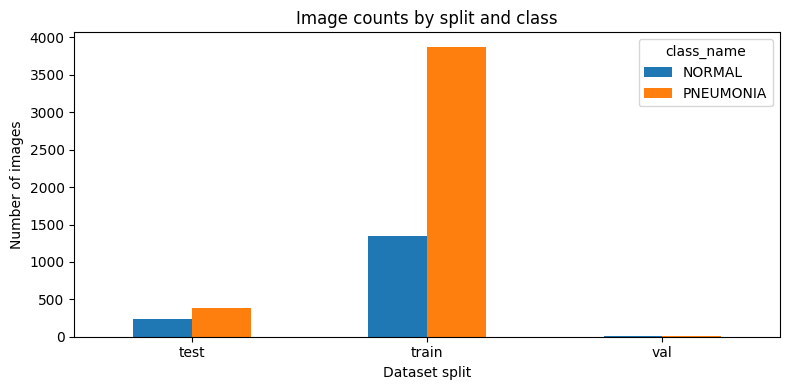

Unreadable files in sample: 0


In [ ]:
# Visualize split/class counts
count_table = pd.crosstab(manifest['split'], manifest['class_name'])
ax = count_table.plot(kind='bar', figsize=(8, 4))
ax.set_title('Image counts by split and class')
ax.set_xlabel('Dataset split')
ax.set_ylabel('Number of images')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Verify a sample of images can be opened
bad_files = []
for p in manifest['image_path'].sample(min(100, len(manifest)), random_state=SEED):
    try:
        with Image.open(p) as im:
            im.verify()
    except Exception:
        bad_files.append(p)

print("Unreadable files in sample:", len(bad_files))
if bad_files:
    print(*bad_files[:10], sep='\n')

## 4. Create train, validation and test sets

- If the supplied `val/` split has at least 100 images and both classes (or you used the flat layout, where val/ was created for you), it is used as validation.
- If `val/` is missing or unusually tiny (as in some Kermany copies), a stratified validation split is drawn from `train/`.
- The supplied `test/` split is never used for training or model selection.
- This dataset does not provide reliable patient IDs in the folder structure. The split is therefore image-level, not guaranteed patient-level. State this limitation in any report.

In [ ]:
train_all = manifest[manifest.split == 'train'].copy()
test_df = manifest[manifest.split == 'test'].copy()
val_existing = manifest[manifest.split == 'val'].copy()

if train_all.empty or test_df.empty:
    raise ValueError("Both train/ and test/ folders must contain images from NORMAL and PNEUMONIA.")

if set(train_all.label.unique()) != {0, 1} or set(test_df.label.unique()) != {0, 1}:
    raise ValueError("Train and test must each contain both NORMAL and PNEUMONIA classes.")

if (LAYOUT == 'flat' or len(val_existing) >= 100) and set(val_existing.label.unique()) == {0, 1}:
    train_df = train_all.copy()
    val_df = val_existing.copy()
    validation_source = "provided val/ folder"
else:
    train_df, val_df = train_test_split(
        train_all,
        test_size=0.15,
        random_state=SEED,
        stratify=train_all['label']
    )
    validation_source = "15% stratified split from train/ (provided val/ was absent or too small)"

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Validation source:", validation_source)
for name, frame in [('Train', train_df), ('Validation', val_df), ('Test', test_df)]:
    print(f"{name}: {len(frame)} images | counts: {frame.label.value_counts().sort_index().to_dict()}")

Validation source: 15% stratified split from train/ (provided val/ was absent or too small)
Train: 4433 images | counts: {0: 1140, 1: 3293}
Validation: 783 images | counts: {0: 201, 1: 582}
Test: 624 images | counts: {0: 234, 1: 390}


## 5. Image preprocessing and DataLoaders

Images are resized to 224×224 and normalized using ImageNet statistics because DenseNet121 is initialized with ImageNet pretrained weights. Mild augmentation is applied to training images only.

In [ ]:
IMG_SIZE = 224
BATCH_SIZE = 32 if DEVICE.type == 'cuda' else 8
NUM_WORKERS = 2

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomRotation(degrees=7),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.08, contrast=0.08),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

class ChestXrayDataset(Dataset):
    def __init__(self, frame, transform=None):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        image = Image.open(row.image_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        label = torch.tensor(float(row.label), dtype=torch.float32)
        return image, label, row.image_path

train_ds = ChestXrayDataset(train_df, train_transform)
val_ds = ChestXrayDataset(val_df, eval_transform)
test_ds = ChestXrayDataset(test_df, eval_transform)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == 'cuda'))
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == 'cuda'))
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == 'cuda'))

print("Loaders ready.")
print("Batches — train:", len(train_loader), "validation:", len(val_loader), "test:", len(test_loader))

Loaders ready.
Batches — train: 555 validation: 98 test: 78


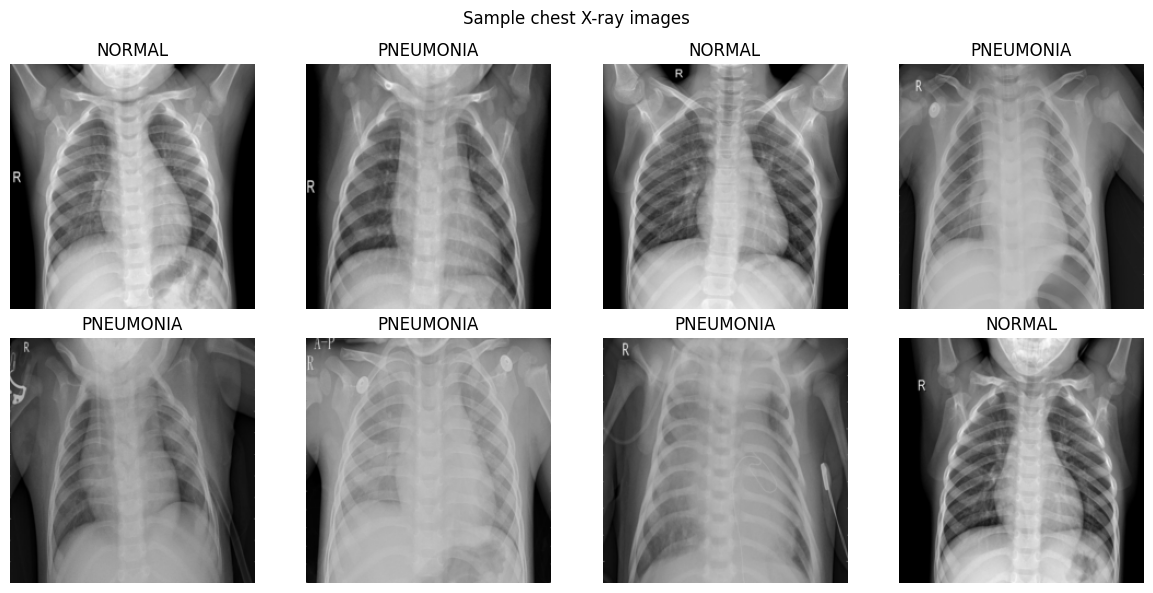

In [ ]:
# Display a few training images before normalization is applied
preview_ds = ChestXrayDataset(train_df, transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor()
]))
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, idx in zip(axes.flat, np.random.choice(len(preview_ds), min(8, len(preview_ds)), replace=False)):
    image, label, path = preview_ds[idx]
    ax.imshow(image.permute(1, 2, 0).numpy(), cmap='gray')
    ax.set_title("PNEUMONIA" if int(label.item()) == 1 else "NORMAL")
    ax.axis('off')
plt.suptitle("Sample chest X-ray images")
plt.tight_layout()
plt.show()

## 6. Build DenseNet121

We use transfer learning with ImageNet pretrained DenseNet121. The classifier head is replaced with a single logit for binary classification. The final dense block and classifier are trainable; earlier feature layers are initially frozen to reduce training time and overfitting.

In [ ]:
from torchvision.models import DenseNet121_Weights

weights = DenseNet121_Weights.DEFAULT
model = models.densenet121(weights=weights)

# Freeze the feature extractor first
for param in model.features.parameters():
    param.requires_grad = False

# Unfreeze the final dense block and final normalization
for name, param in model.features.named_parameters():
    if name.startswith('denseblock4') or name.startswith('norm5'):
        param.requires_grad = True

in_features = model.classifier.in_features
model.classifier = nn.Sequential(
    nn.Dropout(p=0.35),
    nn.Linear(in_features, 1)
)
model = model.to(DEVICE)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"Trainable parameters: {trainable:,} / {total:,}")

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 152MB/s]


Trainable parameters: 2,161,153 / 6,954,881


## 7. Loss, optimizer and training functions

The positive-class weight is computed from the training split to account for class imbalance. We select the best checkpoint using validation AUROC (with validation loss as a fallback if AUROC cannot be calculated).

In [ ]:
train_counts = train_df.label.value_counts().to_dict()
neg_count = train_counts.get(0, 0)
pos_count = train_counts.get(1, 0)
pos_weight = torch.tensor([neg_count / max(pos_count, 1)], dtype=torch.float32, device=DEVICE)

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=1e-4,
    weight_decay=1e-4
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='max', factor=0.5, patience=2
)

def run_one_epoch(model, loader, training=False):
    model.train(training)
    running_loss = 0.0
    all_labels, all_probs = [], []

    for images, labels, _ in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = model(images).squeeze(1)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()

        probs = torch.sigmoid(logits)
        running_loss += loss.item() * images.size(0)
        all_labels.extend(labels.detach().cpu().numpy().astype(int).tolist())
        all_probs.extend(probs.detach().cpu().numpy().tolist())

    avg_loss = running_loss / max(1, len(loader.dataset))
    y_true = np.asarray(all_labels)
    y_prob = np.asarray(all_probs)
    y_pred = (y_prob >= 0.5).astype(int)

    auc = roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) == 2 else np.nan
    metrics = {
        'loss': avg_loss,
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred, zero_division=0),
        'f1': f1_score(y_true, y_pred, zero_division=0),
        'auroc': auc
    }
    return metrics, y_true, y_prob

print("Training functions ready.")

Training functions ready.


## 8. Train the model

Start with up to 5 epochs. Early stopping will stop training if validation AUROC does not improve for 4 epochs. On a T4 GPU, runtime depends on dataset size and Colab availability. If the session disconnects, rerun setup and load the saved checkpoint if available.

In [ ]:
EPOCHS = 5
PATIENCE = 3
best_auc = -np.inf
best_val_loss = np.inf
epochs_without_improvement = 0
history = []

OUTPUT_DIR = Path('/content/pneumonia_project_outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
BEST_MODEL_PATH = OUTPUT_DIR / 'best_densenet121_pneumonia.pth'

start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    train_metrics, _, _ = run_one_epoch(model, train_loader, training=True)
    val_metrics, _, _ = run_one_epoch(model, val_loader, training=False)

    current_auc = val_metrics['auroc']
    score = current_auc if not np.isnan(current_auc) else -val_metrics['loss']
    scheduler.step(score)

    row = {'epoch': epoch}
    row.update({f'train_{k}': v for k, v in train_metrics.items()})
    row.update({f'val_{k}': v for k, v in val_metrics.items()})
    history.append(row)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"train loss {train_metrics['loss']:.4f} | "
        f"val loss {val_metrics['loss']:.4f} | "
        f"val AUROC {val_metrics['auroc']:.4f} | "
        f"val F1 {val_metrics['f1']:.4f}"
    )

    improved = (current_auc > best_auc) if not np.isnan(current_auc) else (val_metrics['loss'] < best_val_loss)
    if improved:
        best_auc = current_auc if not np.isnan(current_auc) else best_auc
        best_val_loss = min(best_val_loss, val_metrics['loss'])
        torch.save(model.state_dict(), BEST_MODEL_PATH)
        epochs_without_improvement = 0
        print("  Saved new best checkpoint.")
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping triggered.")
        break

print(f"Training time: {(time.time() - start_time)/60:.1f} minutes")
print("Best checkpoint:", BEST_MODEL_PATH)

history_df = pd.DataFrame(history)
display(history_df.round(4))
history_df.to_csv(OUTPUT_DIR / 'training_history.csv', index=False)

model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=DEVICE))

Epoch 01/5 | train loss 0.0577 | val loss 0.0484 | val AUROC 0.9949 | val F1 0.9748
  Saved new best checkpoint.
Epoch 02/5 | train loss 0.0465 | val loss 0.0403 | val AUROC 0.9966 | val F1 0.9728
  Saved new best checkpoint.
Epoch 03/5 | train loss 0.0439 | val loss 0.0949 | val AUROC 0.9963 | val F1 0.9805
Epoch 04/5 | train loss 0.0318 | val loss 0.0374 | val AUROC 0.9974 | val F1 0.9801
  Saved new best checkpoint.
Epoch 05/5 | train loss 0.0299 | val loss 0.0856 | val AUROC 0.9970 | val F1 0.9815
Training time: 97.0 minutes
Best checkpoint: /content/pneumonia_project_outputs/best_densenet121_pneumonia.pth


,epoch,train_loss,train_accuracy,train_precision,train_recall,train_f1,train_auroc,val_loss,val_accuracy,val_precision,val_recall,val_f1,val_auroc
0,1,0.0577,0.9648,0.9834,0.9690,0.9761,0.9922,0.0484,0.9630,0.9842,0.9656,0.9748,0.9949
1,2,0.0465,0.9677,0.9858,0.9705,0.9781,0.9949,0.0403,0.9604,0.9928,0.9536,0.9728,0.9966
2,3,0.0439,0.9756,0.9866,0.9806,0.9836,0.9957,0.0949,0.9706,0.9697,0.9914,0.9805,0.9963
3,4,0.0318,0.9801,0.9926,0.9806,0.9866,0.9974,0.0374,0.9706,0.9895,0.9708,0.9801,0.9974
4,5,0.0299,0.9835,0.9921,0.9857,0.9889,0.9980,0.0856,0.9719,0.9636,1.0000,0.9815,0.9970


<All keys matched successfully>

## 9. Plot training curves

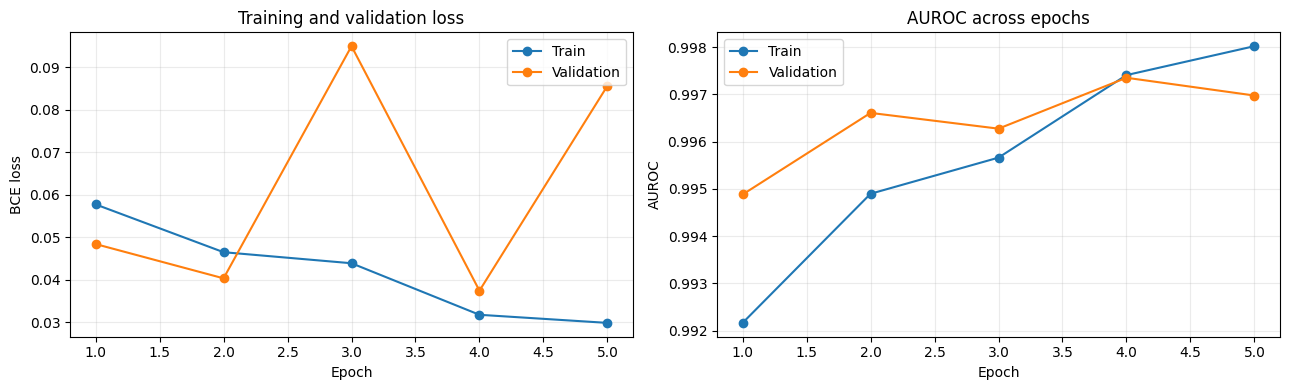

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history_df.epoch, history_df.train_loss, marker='o', label='Train')
axes[0].plot(history_df.epoch, history_df.val_loss, marker='o', label='Validation')
axes[0].set_title('Training and validation loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('BCE loss')
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(history_df.epoch, history_df.train_auroc, marker='o', label='Train')
axes[1].plot(history_df.epoch, history_df.val_auroc, marker='o', label='Validation')
axes[1].set_title('AUROC across epochs')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('AUROC')
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'training_curves.png', dpi=160, bbox_inches='tight')
plt.show()

## 10. Final evaluation on the held-out test set

The test set is evaluated only after model selection is complete. The threshold below is 0.5 for a straightforward baseline; threshold tuning, if needed, must be done using validation data only.

In [ ]:
@torch.no_grad()
def predict_loader(model, loader):
    model.eval()
    ys, probs, paths = [], [], []
    for images, labels, batch_paths in loader:
        images = images.to(DEVICE)
        logits = model(images).squeeze(1)
        batch_probs = torch.sigmoid(logits).cpu().numpy()
        probs.extend(batch_probs.tolist())
        ys.extend(labels.numpy().astype(int).tolist())
        paths.extend(list(batch_paths))
    return np.asarray(ys), np.asarray(probs), paths

y_test, p_test, test_paths = predict_loader(model, test_loader)
y_pred = (p_test >= 0.5).astype(int)

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

test_results = {
    'accuracy': accuracy_score(y_test, y_pred),
    'precision': precision_score(y_test, y_pred, zero_division=0),
    'sensitivity_recall': recall_score(y_test, y_pred, zero_division=0),
    'specificity': tn / max(tn + fp, 1),
    'f1_score': f1_score(y_test, y_pred, zero_division=0),
    'auroc': roc_auc_score(y_test, p_test) if len(np.unique(y_test)) == 2 else np.nan,
    'auprc': average_precision_score(y_test, p_test) if len(np.unique(y_test)) == 2 else np.nan
}

results_df = pd.DataFrame([test_results]).T.rename(columns={0: 'Test result'})
display(results_df.round(4))

print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=['NORMAL', 'PNEUMONIA'], zero_division=0))

print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(cm)

results_df.to_csv(OUTPUT_DIR / 'test_metrics.csv')
with open(OUTPUT_DIR / 'test_metrics.json', 'w') as f:
    json.dump({k: (None if np.isnan(v) else float(v)) for k, v in test_results.items()}, f, indent=2)

,Test result
accuracy,0.8846
precision,0.8457
sensitivity_recall,0.9974
specificity,0.6966
f1_score,0.9153
auroc,0.9515
auprc,0.9619



Classification report:
              precision    recall  f1-score   support

      NORMAL       0.99      0.70      0.82       234
   PNEUMONIA       0.85      1.00      0.92       390

    accuracy                           0.88       624
   macro avg       0.92      0.85      0.87       624
weighted avg       0.90      0.88      0.88       624

Confusion matrix [[TN, FP], [FN, TP]]:
[[163  71]
 [  1 389]]


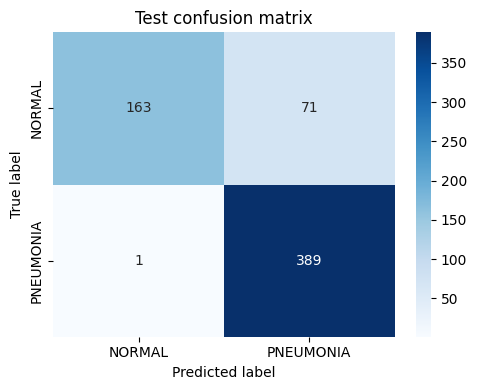

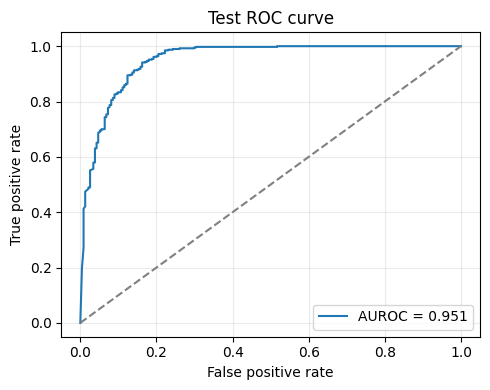

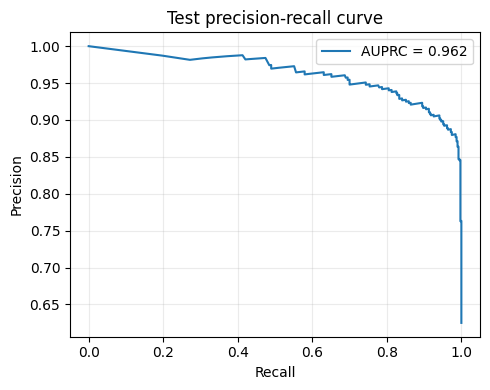

In [ ]:
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['NORMAL', 'PNEUMONIA'],
            yticklabels=['NORMAL', 'PNEUMONIA'])
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.title('Test confusion matrix')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'confusion_matrix.png', dpi=160, bbox_inches='tight')
plt.show()

fpr, tpr, _ = roc_curve(y_test, p_test)
plt.figure(figsize=(5, 4))
plt.plot(fpr, tpr, label=f"AUROC = {test_results['auroc']:.3f}")
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('Test ROC curve')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'roc_curve.png', dpi=160, bbox_inches='tight')
plt.show()

precision, recall, _ = precision_recall_curve(y_test, p_test)
plt.figure(figsize=(5, 4))
plt.plot(recall, precision, label=f"AUPRC = {test_results['auprc']:.3f}")
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Test precision-recall curve')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'precision_recall_curve.png', dpi=160, bbox_inches='tight')
plt.show()

## 11. Save test-set predictions

In [ ]:
predictions_df = pd.DataFrame({
    'image_path': test_paths,
    'true_label': y_test,
    'true_class': ['PNEUMONIA' if x == 1 else 'NORMAL' for x in y_test],
    'p_pneumonia': p_test,
    'predicted_label': y_pred,
    'predicted_class': ['PNEUMONIA' if x == 1 else 'NORMAL' for x in y_pred],
    'correct': (y_test == y_pred)
})
display(predictions_df.head(10))
predictions_df.to_csv(OUTPUT_DIR / 'test_predictions.csv', index=False)

,image_path,true_label,true_class,p_pneumonia,predicted_label,predicted_class,correct
0,/content/local_data/chest_xray/test/PNEUMONIA/...,1,PNEUMONIA,0.998988,1,PNEUMONIA,True
1,/content/local_data/chest_xray/test/PNEUMONIA/...,1,PNEUMONIA,0.941108,1,PNEUMONIA,True
2,/content/local_data/chest_xray/test/PNEUMONIA/...,1,PNEUMONIA,0.999302,1,PNEUMONIA,True
3,/content/local_data/chest_xray/test/PNEUMONIA/...,1,PNEUMONIA,1.000000,1,PNEUMONIA,True
4,/content/local_data/chest_xray/test/PNEUMONIA/...,1,PNEUMONIA,1.000000,1,PNEUMONIA,True
5,/content/local_data/chest_xray/test/PNEUMONIA/...,1,PNEUMONIA,1.000000,1,PNEUMONIA,True
6,/content/local_data/chest_xray/test/PNEUMONIA/...,1,PNEUMONIA,0.999999,1,PNEUMONIA,True
7,/content/local_data/chest_xray/test/PNEUMONIA/...,1,PNEUMONIA,1.000000,1,PNEUMONIA,True
8,/content/local_data/chest_xray/test/PNEUMONIA/...,1,PNEUMONIA,1.000000,1,PNEUMONIA,True
9,/content/local_data/chest_xray/test/PNEUMONIA/...,1,PNEUMONIA,0.996808,1,PNEUMONIA,True


## 12. Grad-CAM explainability

Grad-CAM highlights image regions that contribute to the selected model score. It is a visualization aid, not proof that the model is reasoning clinically correctly. DenseNet may use shortcuts or acquisition artifacts, so inspect examples critically.

/tmp/ipykernel_492/1880338647.py:20: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
  score.backward()


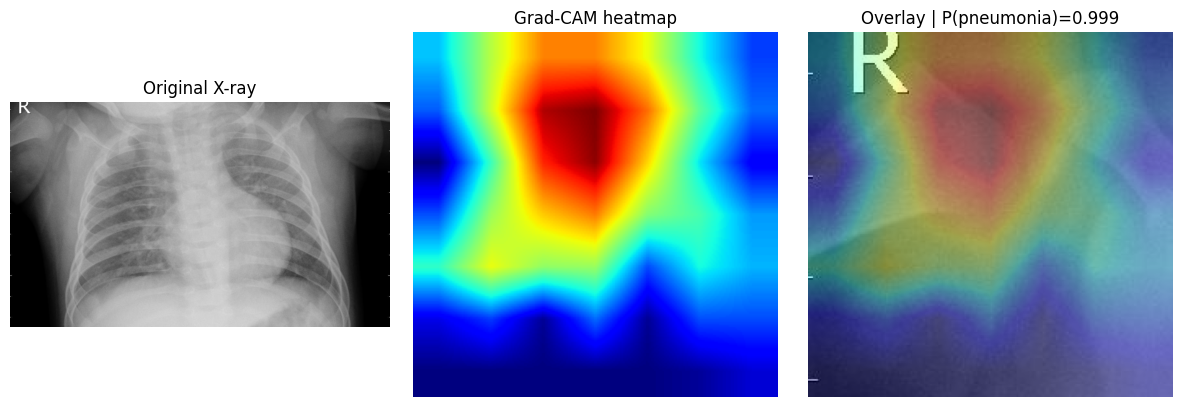

In [ ]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None
        self.gradients = None
        self.fwd_handle = target_layer.register_forward_hook(self._save_activation)
        self.bwd_handle = target_layer.register_full_backward_hook(self._save_gradient)

    def _save_activation(self, module, inp, out):
        self.activations = out

    def _save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def generate(self, input_tensor):
        self.model.eval()
        self.model.zero_grad(set_to_none=True)
        logit = self.model(input_tensor).squeeze()
        score = logit if logit.item() >= 0 else -logit
        score.backward()

        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam = (weights * self.activations).sum(dim=1, keepdim=True)
        cam = torch.relu(cam)
        cam = torch.nn.functional.interpolate(
            cam, size=input_tensor.shape[-2:], mode='bilinear', align_corners=False
        )
        cam = cam.squeeze().detach().cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam, float(torch.sigmoid(logit).detach().cpu())

    def close(self):
        self.fwd_handle.remove()
        self.bwd_handle.remove()

# DenseNet final convolutional feature block
target_layer = model.features.denseblock4
gradcam = GradCAM(model, target_layer)

# Choose one correctly or incorrectly classified test image by index
sample_index = 0
sample_path = test_paths[sample_index]
raw_image = Image.open(sample_path).convert('RGB')
input_tensor = eval_transform(raw_image).unsqueeze(0).to(DEVICE)

heatmap, probability = gradcam.generate(input_tensor)

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.imshow(raw_image, cmap='gray')
plt.title('Original X-ray')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(heatmap, cmap='jet')
plt.title('Grad-CAM heatmap')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(raw_image)
plt.imshow(heatmap, cmap='jet', alpha=0.35)
plt.title(f'Overlay | P(pneumonia)={probability:.3f}')
plt.axis('off')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'gradcam_example.png', dpi=160, bbox_inches='tight')
plt.show()
gradcam.close()

## 13. Reusable single-image prediction function (dataset image or an image in your Drive)

Use `predict_xray(path)` for any image file, or `predict_from_drive(path)` for a single image or a whole folder of images in your Drive. Predictions are model outputs, not medical diagnoses.

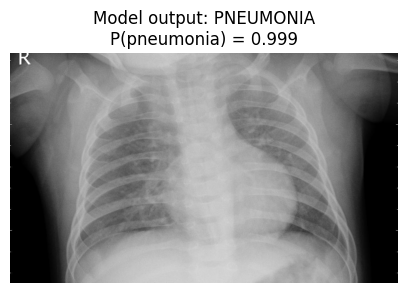

{'predicted_class': 'PNEUMONIA', 'p_pneumonia': 0.9989877343177795}

In [ ]:
@torch.no_grad()
def predict_xray(image_path, threshold=0.5):
    model.eval()
    image = Image.open(image_path).convert('RGB')
    x = eval_transform(image).unsqueeze(0).to(DEVICE)
    probability = torch.sigmoid(model(x).squeeze()).item()
    predicted = 'PNEUMONIA' if probability >= threshold else 'NORMAL'

    plt.figure(figsize=(5, 5))
    plt.imshow(image, cmap='gray')
    plt.title(f"Model output: {predicted}\nP(pneumonia) = {probability:.3f}")
    plt.axis('off')
    plt.show()

    return {'predicted_class': predicted, 'p_pneumonia': probability}

# Example:
predict_xray(test_paths[0])

In [ ]:
def predict_from_drive(path, threshold=0.5):
    """Run the trained model on one image, or on every image in a Drive folder."""
    path = Path(path)
    imgs = [path] if path.is_file() else sorted(p for p in path.rglob('*')
                                               if p.is_file() and not p.name.startswith('.')
                                               and p.suffix.lower() in IMAGE_EXTS)
    if not imgs:
        raise FileNotFoundError(f"No images found at {path}")
    results = {}
    for p in imgs[:20]:                       # cap plots at 20 images per call
        try:
            results[p.name] = predict_xray(p, threshold=threshold)
        except Exception as e:
            print(f"Could not read {p.name}: {e}")
    return results

# Example (edit the path):
# predict_from_drive('/content/drive/MyDrive/my_xrays/example.jpeg')

## 14. Export model and project outputs

This cell saves the trained weights, class mapping, metrics, history, plots and predictions into one ZIP file. You can download it from the Colab file browser or use the download helper below.

In [ ]:
# Save model state and metadata
torch.save({
    'model_state_dict': model.state_dict(),
    'architecture': 'DenseNet121',
    'class_to_label': CLASS_TO_LABEL,
    'image_size': IMG_SIZE,
    'threshold': 0.5
}, OUTPUT_DIR / 'densenet121_pneumonia_checkpoint.pth')

with open(OUTPUT_DIR / 'project_metadata.json', 'w') as f:
    json.dump({
        'project': 'Chest X-ray Pneumonia Detection',
        'dataset': 'Kermany/Kaggle Chest X-Ray',
        'architecture': 'DenseNet121 transfer learning',
        'classes': CLASS_TO_LABEL,
        'image_size': IMG_SIZE,
        'validation_source': validation_source,
        'test_metrics': {k: (None if np.isnan(v) else float(v)) for k, v in test_results.items()},
        'limitations': [
            'Educational/research prototype, not for clinical diagnosis.',
            'Kermany folder dataset does not include paired pre-diagnostic clinical text.',
            'Patient-level separation cannot be guaranteed from folder labels alone.'
        ]
    }, f, indent=2)

import shutil
zip_path = shutil.make_archive('/content/pneumonia_project_outputs', 'zip', OUTPUT_DIR)
print("Created:", zip_path)

from google.colab import files
files.download(zip_path)

Created: /content/pneumonia_project_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 15. Optional: copy results to Google Drive

Drive is already mounted from Section 2. Run this cell to keep the outputs in Drive after the session ends; otherwise just download the ZIP from the previous cell.

In [ ]:
DRIVE_OUTPUT = Path('/content/drive/MyDrive/pneumonia_project_outputs')
DRIVE_OUTPUT.mkdir(parents=True, exist_ok=True)

for item in OUTPUT_DIR.iterdir():
    if item.is_file():
        shutil.copy2(item, DRIVE_OUTPUT / item.name)

print("Outputs copied to:", DRIVE_OUTPUT)
print("Files:", sorted(p.name for p in DRIVE_OUTPUT.iterdir()))

Outputs copied to: /content/drive/MyDrive/pneumonia_project_outputs
Files: ['best_densenet121_pneumonia.pth', 'confusion_matrix.png', 'densenet121_pneumonia_checkpoint.pth', 'gradcam_example.png', 'precision_recall_curve.png', 'project_metadata.json', 'roc_curve.png', 'test_metrics.csv', 'test_metrics.json', 'test_predictions.csv', 'training_curves.png', 'training_history.csv']


# Part B — Multimodal extension: image + clinical text (IU X-Ray)

**What it does:** fuses DenseNet121 image features with a frozen **Bio_ClinicalBERT** embedding of the study's *indication* text (the pre-diagnostic reason for the exam), then compares it against an image-only model on the **same** split.

**Leakage guard (important):** IU X-Ray reports also contain *findings*, *impression*, *Problems* and *MeSH* fields. These describe the diagnosis, so they are used **only to create the label** and are never fed to the text encoder. Using them as input would make the task trivial and the results meaningless.

**Dataset format (IU X-Ray, e.g. the Kaggle "Chest X-rays (Indiana University)" copy)** — put these in one Google Drive folder (set `MM_DRIVE_DIR` below):
1. `indiana_reports.csv` (columns incl. `uid`, `indication`, `findings`, `impression`, `Problems`, `MeSH`)
2. `indiana_projections.csv` (columns `uid`, `filename`, `projection`)
3. the images, either as a **ZIP** (e.g. `images_normalized.zip`) or as an extracted image folder

**Honest caveats:** the pneumonia label here is a weak label derived from the report's problem tags; IU X-Ray has very few pneumonia cases, so test metrics will be noisy — report confidence intervals or treat this as a feasibility study. Indication text is short (e.g. "cough, fever"), so a small gain over image-only is plausible but not guaranteed; report whatever you measure.

**MIMIC-CXR:** it needs credentialed PhysioNet access and a signed data-use agreement, and the full dataset is far too large to upload to Colab. If you have access, create a subset ZIP and build a DataFrame with the columns `uid, image_path, text, label` (label from the CheXpert `Pneumonia` column, text from the report's *indication* section only); everything from the "Train/val/test split" cell onward then works unchanged.

In [ ]:
import os, re, zipfile, shutil
from pathlib import Path
import numpy as np
import pandas as pd
from google.colab import drive

if not Path('/content/drive/MyDrive').exists():
    drive.mount('/content/drive')
IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff', '.webp'}

Mounted at /content/drive


In [ ]:
!pip -q install transformers

In [ ]:
!wget -c "https://openi.nlm.nih.gov/imgs/collections/NLMCXR_reports.tgz" \
     -O /content/NLMCXR_reports.tgz

!wget -c "https://openi.nlm.nih.gov/imgs/collections/NLMCXR_png.tgz" \
     -O /content/NLMCXR_png.tgz

--2026-11-08 11:16:45--  https://openi.nlm.nih.gov/imgs/collections/NLMCXR_reports.tgz
Resolving openi.nlm.nih.gov (openi.nlm.nih.gov)... 3.170.185.56, 3.170.185.47, 3.170.185.94, ...
Connecting to openi.nlm.nih.gov (openi.nlm.nih.gov)|3.170.185.56|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 13854 (14K) [text/html]
Saving to: ‘/content/NLMCXR_reports.tgz’

/content/NLMCXR_rep 100%[===================>]  13.53K  --.-KB/s    in 0s      

2026-11-08 11:16:45 (34.9 MB/s) - ‘/content/NLMCXR_reports.tgz’ saved [13854/13854]

--2026-11-08 11:16:45--  https://openi.nlm.nih.gov/imgs/collections/NLMCXR_png.tgz
Resolving openi.nlm.nih.gov (openi.nlm.nih.gov)... 3.170.185.56, 3.170.185.47, 3.170.185.94, ...
Connecting to openi.nlm.nih.gov (openi.nlm.nih.gov)|3.170.185.56|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 13854 (14K) [text/html]
Saving to: ‘/content/NLMCXR_png.tgz’

/content/NLMCXR_png 100%[===================>]  13.53K  --.-KB/s

In [ ]:
!mkdir -p /content/IU_XRay/reports
!mkdir -p /content/IU_XRay/images

!tar -xzf /content/NLMCXR_reports.tgz -C /content/IU_XRay/reports
!tar -xzf /content/NLMCXR_png.tgz -C /content/IU_XRay/images


gzip: stdin: not in gzip format
tar: Child returned status 1
tar: Error is not recoverable: exiting now

gzip: stdin: not in gzip format
tar: Child returned status 1
tar: Error is not recoverable: exiting now


In [ ]:
import re
import io
import os
import zipfile
import xml.etree.ElementTree as ET
from pathlib import Path
import torch.nn.functional as F
from google.colab import auth
import google.auth
from googleapiclient.discovery import build
from googleapiclient.http import MediaIoBaseDownload

# Your exact IU-Xray Google Drive folder.
IU_XRAY_FOLDER_ID = '16dLxw-zMNF8v2b_wIiML_iEsl0QdMy-s'

print('Authorizing access to the Google Drive folder...')
auth.authenticate_user()
creds, _ = google.auth.default(scopes=['https://www.googleapis.com/auth/drive.readonly'])
drive_service = build('drive', 'v3', credentials=creds, cache_discovery=False)

def list_drive_tree(root_folder_id):
    """Recursively list files below the supplied Drive folder."""
    all_files, folders_to_visit = [], [root_folder_id]
    visited = set()
    while folders_to_visit:
        parent_id = folders_to_visit.pop()
        if parent_id in visited:
            continue
        visited.add(parent_id)
        page_token = None
        while True:
            response = drive_service.files().list(
                q=f"'{parent_id}' in parents and trashed = false",
                fields='nextPageToken, files(id,name,mimeType,size,shortcutDetails)',
                pageSize=1000, pageToken=page_token,
                supportsAllDrives=True, includeItemsFromAllDrives=True
            ).execute()
            for item in response.get('files', []):
                if item.get('mimeType') == 'application/vnd.google-apps.folder':
                    folders_to_visit.append(item['id'])
                else:
                    all_files.append(item)
            page_token = response.get('nextPageToken')
            if not page_token:
                break
    return all_files

def drive_download(file_id, destination):
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    request = drive_service.files().get_media(fileId=file_id, supportsAllDrives=True)
    with open(destination, 'wb') as handle:
        downloader = MediaIoBaseDownload(handle, request, chunksize=1024 * 1024)
        done = False
        while not done:
            _, done = downloader.next_chunk()
    return destination

try:
    drive_items = list_drive_tree(IU_XRAY_FOLDER_ID)
except Exception as exc:
    raise RuntimeError(
        'Could not read your IU-Xray Drive folder. Authorize the Google account that '
        'has access to the folder. Original error: ' + str(exc)
    )

if not drive_items:
    raise FileNotFoundError(
        'The linked Drive folder is empty or not accessible to the authorized account. '
        'Open the link with the same Google account used in Colab.'
    )

MM_LOCAL = Path('/content/iu_xray_local')
MM_LOCAL.mkdir(parents=True, exist_ok=True)

# Print a useful inventory before parsing. This makes layout problems diagnosable.
print(f'Found {len(drive_items)} files under the linked folder.')
from collections import Counter
print('File types:', Counter(Path(x['name']).suffix.lower() for x in drive_items).most_common(15))
print('Sample files:')
for item in drive_items[:30]:
    print(' -', item['name'], '|', item['mimeType'])

# IU-Xray is distributed in two common layouts:
# (1) processed CSVs: indiana_reports.csv + indiana_projections.csv + image files
# (2) original OpenI archive: NLMCXR_reports/*.xml + NLMCXR_png/*.png
IMAGE_EXTENSIONS = {'.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff'}
image_items = [x for x in drive_items if Path(x['name']).suffix.lower() in IMAGE_EXTENSIONS]
xml_items = [x for x in drive_items if Path(x['name']).suffix.lower() == '.xml']
zip_items = [x for x in drive_items if Path(x['name']).suffix.lower() == '.zip']

# If the images/XML are archived, extract them locally first.
if (not image_items or not xml_items) and zip_items:
    for z_item in zip_items:
        zip_path = drive_download(z_item['id'], MM_LOCAL / z_item['name'])
        extract_dir = MM_LOCAL / (Path(z_item['name']).stem + '_extracted')
        extract_dir.mkdir(parents=True, exist_ok=True)
        try:
            with zipfile.ZipFile(zip_path) as zf:
                zf.extractall(extract_dir)
        except zipfile.BadZipFile:
            print('Skipping non-standard ZIP:', z_item['name'])

# Index extracted files from archives as well as Drive files.
local_images = [p for p in MM_LOCAL.rglob('*') if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS]
local_xml = [p for p in MM_LOCAL.rglob('*.xml') if p.is_file()]
image_index = {}
for item in image_items:
    image_index.setdefault(Path(item['name']).name.lower(), item)
for path in local_images:
    image_index.setdefault(path.name.lower(), path)
xml_sources = [(x['name'], x) for x in xml_items] + [(p.name, p) for p in local_xml]

def resolve_image(filename):
    if not filename:
        return None
    name = Path(str(filename).strip()).name.lower()
    if name in image_index:
        return image_index[name]
    # XML parentImage IDs often omit the .png extension.
    stem = Path(name).stem
    for ext in IMAGE_EXTENSIONS:
        candidate = stem + ext
        if candidate in image_index:
            return image_index[candidate]
    return None

def xml_text(element, tag):
    found = element.find('.//' + tag)
    if found is None:
        # Namespace-tolerant fallback.
        found = next((x for x in element.iter() if x.tag.split('}')[-1].lower() == tag.lower()), None)
    if found is None:
        return ''
    return ' '.join(t.strip() for t in found.itertext() if t and t.strip())

# Prefer the processed CSV format when both expected tables are available.
csv_items = [x for x in drive_items if Path(x['name']).suffix.lower() == '.csv']
rep_candidates = [x for x in csv_items if 'report' in x['name'].lower()]
proj_candidates = [x for x in csv_items if 'projection' in x['name'].lower()]
records = []

if rep_candidates and proj_candidates:
    rep_file = rep_candidates[0]
    proj_file = proj_candidates[0]
    rep_csv = drive_download(rep_file['id'], MM_LOCAL / rep_file['name'])
    proj_csv = drive_download(proj_file['id'], MM_LOCAL / proj_file['name'])
    print('Using processed CSV format:', rep_file['name'], 'and', proj_file['name'])

    reports = pd.read_csv(rep_csv)
    proj = pd.read_csv(proj_csv)
    reports.columns = [str(c).strip().lower() for c in reports.columns]
    proj.columns = [str(c).strip().lower() for c in proj.columns]

    if 'uid' not in reports.columns or 'uid' not in proj.columns:
        raise ValueError("Both CSVs must contain a 'uid' column.")
    if 'filename' not in proj.columns or 'projection' not in proj.columns:
        raise ValueError(
            "Projection CSV must contain 'filename' and 'projection'. Found: "
            + str(list(proj.columns))
        )
    if 'indication' not in reports.columns:
        raise ValueError("Reports CSV has no 'indication' column.")

    proj['projection'] = proj['projection'].fillna('').astype(str).str.strip().str.lower()
    frontal = proj[proj['projection'].str.contains('frontal|\bap\b|\bpa\b', regex=True, na=False)].copy()
    if frontal.empty:
        frontal = proj.copy()
    frontal = frontal.drop_duplicates('uid', keep='first')
    reports['uid'] = reports['uid'].astype(str)
    frontal['uid'] = frontal['uid'].astype(str)
    joined = frontal.merge(reports, on='uid', how='inner', suffixes=('_projection', '_report'))

    for _, row in joined.iterrows():
        image_item = resolve_image(row.get('filename', ''))
        if image_item is None:
            continue
        problem = str(row.get('problems', '') or '')
        mesh = str(row.get('mesh', '') or '')
        label = int(bool(re.search(r'\bpneumonia\b', (problem + ' ' + mesh).lower())))
        indication = str(row.get('indication', '') or '')
        records.append({
            'uid': str(row['uid']), 'image_item': image_item,
            'label': label, 'text': indication
        })

elif xml_sources:
    print(f'No matching report/projection CSV pair found. Parsing {len(xml_sources)} original IU-Xray XML reports.')
    for xml_name, xml_source in xml_sources:
        try:
            if isinstance(xml_source, dict):
                xml_path = drive_download(xml_source['id'], MM_LOCAL / 'xml' / xml_source['name'])
            else:
                xml_path = xml_source
            root = ET.parse(xml_path).getroot()
        except Exception as exc:
            print('Skipping unreadable XML:', xml_name, '|', exc)
            continue

        uid = xml_text(root, 'uId') or Path(xml_name).stem
        indication = xml_text(root, 'indication')
        # Use the report's diagnosis tags/MeSH terms only to form the weak label.
        diagnosis_text = ' '.join(
            xml_text(root, tag) for tag in ['MeSH', 'Problems', 'problem', 'diagnosis']
        ).lower()
        label = int(bool(re.search(r'\bpneumonia\b', diagnosis_text)))

        image_ids = []
        for node in root.iter():
            if node.tag.split('}')[-1].lower() == 'parentimage':
                image_id = node.attrib.get('id') or node.attrib.get('image')
                if not image_id:
                    image_id = ' '.join(node.itertext()).strip()
                if image_id:
                    image_ids.append(image_id)

        # If the XML has no parentImage tags, try the report UID as the image stem.
        if not image_ids:
            image_ids = [uid]
        for image_id in image_ids:
            image_item = resolve_image(image_id)
            if image_item is None:
                continue
            records.append({
                'uid': str(uid), 'image_item': image_item,
                'label': label, 'text': indication
            })
else:
    raise FileNotFoundError(
        'Could not identify the IU-Xray dataset layout. The folder must contain either '
        'indiana_reports.csv + indiana_projections.csv, or the original NLMCXR_reports XML '
        'files together with NLMCXR_png images. See the file inventory printed above.'
    )

if not records:
    raise FileNotFoundError(
        'Metadata was found, but no report-to-image matches were created. '
        'Check whether the XML parentImage IDs or CSV filenames match the image filenames. '
        'The cell printed a file inventory above to help identify the layout.'
    )

# Keep one frontal/image record per study UID and materialize Drive images locally.
mm = pd.DataFrame(records).drop_duplicates('uid', keep='first').reset_index(drop=True)
resolved_paths = []
for idx, item in enumerate(mm['image_item']):
    if isinstance(item, dict):
        local_path = MM_LOCAL / 'images' / f'{idx:06d}_{Path(item["name"]).name}'
        if not local_path.exists():
            drive_download(item['id'], local_path)
        resolved_paths.append(str(local_path))
    else:
        resolved_paths.append(str(item))
mm['image_path'] = resolved_paths
mm['text'] = mm['text'].fillna('').astype(str).map(
    lambda value: re.sub(r'\s+', ' ', re.sub(r'x{2,}', ' ', value, flags=re.I)).strip()
    or 'no indication provided'
)
mm['row_id'] = np.arange(len(mm))
mm = mm[['uid', 'image_path', 'label', 'text', 'row_id']].copy()

print(f'Matched IU-Xray studies/images: {len(mm)}')
print('Weak-label counts (0 = no pneumonia tag, 1 = pneumonia tag):')
print(mm['label'].value_counts().sort_index())
print('Example records:')
display(mm[['uid', 'text', 'label']].head(10))

positive_count = int(mm['label'].sum())
negative_count = int((mm['label'] == 0).sum())
if positive_count < 3 or negative_count < 3:
    raise ValueError(
        f'Not enough positive/negative examples for a stratified split '
        f'(positive={positive_count}, negative={negative_count}). '
        'The IU-Xray metadata may not contain pneumonia tags. Do not train or report '
        'classification metrics until labels have been verified.'
    )
if len(mm) < 30:
    print('WARNING: Very small matched dataset; performance estimates will be highly uncertain.')

TEXT_INPUT_COLUMNS = ['indication']
LEAKAGE_COLUMNS = {'findings', 'impression', 'problems', 'mesh'}
assert not (set(TEXT_INPUT_COLUMNS) & LEAKAGE_COLUMNS)


Authorizing access to the Google Drive folder...


Found 29880 files under the linked folder.
File types: [('.png', 29879), ('.csv', 1)]
Sample files:
 - cleaned_dataset.csv | text/csv
 - CXR2594_IM-1085-2001.png | image/png
 - CXR1464_IM-0301-2001.png | image/png
 - CXR1863_IM-0558-3001.png | image/png
 - CXR3705_IM-1851-1001-0001.png | image/png
 - CXR1207_IM-0140-0001-0001.png | image/png
 - CXR890_IM-2403-2001.png | image/png
 - CXR1237_IM-0159-1002.png | image/png
 - CXR2162_IM-0779-1001.png | image/png
 - CXR296_IM-1354-1002.png | image/png
 - CXR953_IM-2447-1001.png | image/png
 - CXR619_IM-2202-1002.png | image/png
 - CXR815_IM-2346-1001.png | image/png
 - CXR2481_IM-1010-12012.png | image/png
 - CXR2743_IM-1197-1001.png | image/png
 - CXR2274_IM-0861-1001.png | image/png
 - CXR2668_IM-1147-2001.png | image/png
 - CXR1223_IM-0150-2001.png | image/png
 - CXR2178_IM-0790-1001.png | image/png
 - CXR2243_IM-0840-1001.png | image/png
 - CXR2054_IM-0692-0001-0002.png | image/png
 - CXR3136_IM-1475-1001.png | image/png
 - CXR931_IM-24

FileNotFoundError: Could not identify the IU-Xray dataset layout. The folder must contain either indiana_reports.csv + indiana_projections.csv, or the original NLMCXR_reports XML files together with NLMCXR_png images. See the file inventory printed above.

In [ ]:
import re
import io
import os
import zipfile
import torch.nn.functional as F
from google.colab import auth
import google.auth
from googleapiclient.discovery import build
from googleapiclient.http import MediaIoBaseDownload

# IU-Xray folder supplied by you. This uses the folder ID directly, so no
# MyDrive path guessing or renaming is needed.
IU_XRAY_FOLDER_ID = '16dLxw-zMNF8v2b_wIiML_iEsl0QdMy-s'

print('Authorizing access to the Google Drive folder...')
auth.authenticate_user()
creds, _ = google.auth.default(scopes=['https://www.googleapis.com/auth/drive.readonly'])
drive_service = build('drive', 'v3', credentials=creds, cache_discovery=False)

# Google Drive API lists direct children only, so traverse all subfolders.
def list_drive_tree(root_folder_id):
    all_files = []
    folders_to_visit = [root_folder_id]
    while folders_to_visit:
        parent_id = folders_to_visit.pop()
        page_token = None
        while True:
            response = drive_service.files().list(
                q=f"'{parent_id}' in parents and trashed = false",
                fields='nextPageToken, files(id,name,mimeType,size,shortcutDetails)',
                pageSize=1000,
                pageToken=page_token,
                supportsAllDrives=True,
                includeItemsFromAllDrives=True,
            ).execute()
            for item in response.get('files', []):
                if item.get('mimeType') == 'application/vnd.google-apps.folder':
                    folders_to_visit.append(item['id'])
                else:
                    all_files.append(item)
            page_token = response.get('nextPageToken')
            if not page_token:
                break
    return all_files

def drive_download(file_id, destination):
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    request = drive_service.files().get_media(fileId=file_id, supportsAllDrives=True)
    with open(destination, 'wb') as handle:
        downloader = MediaIoBaseDownload(handle, request, chunksize=1024 * 1024)
        done = False
        while not done:
            _, done = downloader.next_chunk()
    return destination

try:
    drive_items = list_drive_tree(IU_XRAY_FOLDER_ID)
except Exception as exc:
    raise RuntimeError(
        'Could not read the IU-Xray Drive folder. In the Google authorization prompt, '
        'choose the Google account that can open your folder link. Also verify the folder '
        'is shared with that account. Original error: ' + str(exc)
    )

if not drive_items:
    raise FileNotFoundError(
        'No files were found in the supplied Drive folder. Check that the folder link opens '
        'for the Google account you authorized in Colab.'
    )

# Identify the IU-Xray CSVs anywhere in the folder tree.
def find_drive_file(tokens):
    candidates = [x for x in drive_items if all(t in x['name'].lower() for t in tokens)]
    return candidates[0] if candidates else None

rep_file = find_drive_file(['report', '.csv'])
proj_file = find_drive_file(['projection', '.csv'])
if rep_file is None or proj_file is None:
    print('Files discovered in the linked folder (first 60):')
    for item in drive_items[:60]:
        print(' -', item['name'], '|', item['mimeType'])
    raise FileNotFoundError(
        "Could not find both report and projection CSVs in the supplied folder. "
        "Expected files similar to 'indiana_reports.csv' and 'indiana_projections.csv'."
    )

MM_LOCAL = Path('/content/iu_xray_local')
MM_LOCAL.mkdir(parents=True, exist_ok=True)
rep_csv = drive_download(rep_file['id'], MM_LOCAL / rep_file['name'])
proj_csv = drive_download(proj_file['id'], MM_LOCAL / proj_file['name'])
print('Reports CSV:', rep_file['name'])
print('Projections CSV:', proj_file['name'])

reports = pd.read_csv(rep_csv)
proj = pd.read_csv(proj_csv)
reports.columns = [str(c).strip().lower() for c in reports.columns]
proj.columns = [str(c).strip().lower() for c in proj.columns]

if 'uid' not in reports.columns or 'uid' not in proj.columns:
    raise ValueError("Both IU-Xray CSV files must contain a 'uid' column.")
if 'filename' not in proj.columns:
    raise ValueError(f"Projection CSV needs a 'filename' column. Found: {list(proj.columns)}")
if 'projection' not in proj.columns:
    raise ValueError(f"Projection CSV needs a 'projection' column. Found: {list(proj.columns)}")
if 'indication' not in reports.columns:
    raise ValueError(
        "The reports CSV has no 'indication' column. Found columns: " + str(list(reports.columns))
    )

# Keep frontal/AP/PA projections and match them to the report records.
proj['projection'] = proj['projection'].fillna('').astype(str).str.strip().str.lower()
frontal = proj[proj['projection'].str.contains('frontal', na=False)].copy()
if frontal.empty:
    frontal = proj[proj['projection'].str.fullmatch(r'ap|pa', na=False)].copy()
if frontal.empty:
    raise ValueError(
        'No frontal/AP/PA projections found. Projection values are: '
        + str(proj['projection'].value_counts().head(20).to_dict())
    )
frontal = frontal.drop_duplicates('uid', keep='first')
reports['uid'] = reports['uid'].astype(str)
frontal['uid'] = frontal['uid'].astype(str)
mm = frontal.merge(reports, on='uid', how='inner', suffixes=('_projection', '_report'))

# Build a Drive filename index for images in the folder tree. If the images are
# stored in ZIP archives instead, download and extract those archives as fallback.
IMAGE_EXTENSIONS = {'.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff'}
image_items = [x for x in drive_items if Path(x['name']).suffix.lower() in IMAGE_EXTENSIONS]
image_index = {}
for item in image_items:
    image_index.setdefault(Path(item['name']).name.lower(), item)

if not image_index:
    zip_items = [x for x in drive_items if Path(x['name']).suffix.lower() == '.zip']
    if not zip_items:
        raise FileNotFoundError(
            'No image files or ZIP archives were found in the supplied IU-Xray folder.'
        )
    for z_item in zip_items:
        zip_path = drive_download(z_item['id'], MM_LOCAL / z_item['name'])
        extract_dir = MM_LOCAL / (Path(z_item['name']).stem + '_extracted')
        extract_dir.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(zip_path) as zf:
            zf.extractall(extract_dir)
    extracted_images = [p for p in MM_LOCAL.rglob('*') if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS]
    for path in extracted_images:
        image_index.setdefault(path.name.lower(), path)

# Download only the images referenced by frontal projection rows (rather than every file).
def lookup_image(filename):
    if pd.isna(filename):
        return None
    return image_index.get(Path(str(filename).strip()).name.lower())

mm['_image_item'] = mm['filename'].map(lookup_image)
missing_images = int(mm['_image_item'].isna().sum())
mm = mm.dropna(subset=['_image_item']).copy().reset_index(drop=True)

resolved_paths = []
for idx, item in enumerate(mm['_image_item']):
    if isinstance(item, dict):
        # Add a stable index to avoid collisions when two subfolders contain the same basename.
        local_path = MM_LOCAL / 'images' / f'{idx:06d}_{Path(item["name"]).name}'
        if not local_path.exists():
            drive_download(item['id'], local_path)
        resolved_paths.append(str(local_path))
    else:
        resolved_paths.append(str(item))
mm['image_path'] = resolved_paths
mm.drop(columns=['_image_item'], inplace=True)

# Diagnosis-bearing tags are used only for weak labels, never as model input.
def get_text_column(frame, col):
    if col in frame.columns:
        return frame[col].fillna('').astype(str)
    return pd.Series('', index=frame.index, dtype='object')

problem_text = get_text_column(mm, 'problems')
mesh_text = get_text_column(mm, 'mesh')
tag_text = (problem_text + ' ' + mesh_text).str.lower()
mm['label'] = tag_text.str.contains(r'\bpneumonia\b', regex=True).astype(int)

def clean_indication(value):
    value = re.sub(r'x{2,}', ' ', str(value), flags=re.I)
    value = re.sub(r'\s+', ' ', value).strip()
    return value if value and value.lower() != 'nan' else 'no indication provided'

mm['text'] = get_text_column(mm, 'indication').map(clean_indication)
mm['row_id'] = np.arange(len(mm))

print(f'Matched studies with a frontal image: {len(mm)}')
print(f'Projection rows without a matching image: {missing_images}')
print('Weak-label counts (0 = no pneumonia tag, 1 = pneumonia tag):')
print(mm['label'].value_counts().sort_index())
print('Indication examples:')
display(mm[['uid', 'text', 'label']].head(10))

positive_count = int(mm['label'].sum())
negative_count = int((mm['label'] == 0).sum())
if positive_count < 3 or negative_count < 3:
    raise ValueError(
        f'Not enough examples for a stratified train/validation/test split '
        f'(positive={positive_count}, negative={negative_count}). IU-Xray pneumonia tags may be sparse '
        'or use a different tag format. Inspect the Problems/MeSH columns and label counts.'
    )
if len(mm) < 30:
    print('WARNING: Very small matched dataset; expect highly uncertain results.')

TEXT_INPUT_COLUMNS = ['indication']
LEAKAGE_COLUMNS = {'findings', 'impression', 'problems', 'mesh'}
assert not (set(TEXT_INPUT_COLUMNS) & LEAKAGE_COLUMNS)


Authorizing access to the Google Drive folder...


Files discovered in the linked folder (first 60):
 - cleaned_dataset.csv | text/csv
 - CXR2594_IM-1085-2001.png | image/png
 - CXR1464_IM-0301-2001.png | image/png
 - CXR1863_IM-0558-3001.png | image/png
 - CXR3705_IM-1851-1001-0001.png | image/png
 - CXR1207_IM-0140-0001-0001.png | image/png
 - CXR890_IM-2403-2001.png | image/png
 - CXR1237_IM-0159-1002.png | image/png
 - CXR2162_IM-0779-1001.png | image/png
 - CXR296_IM-1354-1002.png | image/png
 - CXR953_IM-2447-1001.png | image/png
 - CXR619_IM-2202-1002.png | image/png
 - CXR815_IM-2346-1001.png | image/png
 - CXR2481_IM-1010-12012.png | image/png
 - CXR2743_IM-1197-1001.png | image/png
 - CXR2274_IM-0861-1001.png | image/png
 - CXR2668_IM-1147-2001.png | image/png
 - CXR1223_IM-0150-2001.png | image/png
 - CXR2178_IM-0790-1001.png | image/png
 - CXR2243_IM-0840-1001.png | image/png
 - CXR2054_IM-0692-0001-0002.png | image/png
 - CXR3136_IM-1475-1001.png | image/png
 - CXR931_IM-2429-1001.png | image/png
 - CXR546_IM-2150-2001.png

FileNotFoundError: Could not find both report and projection CSVs in the supplied folder. Expected files similar to 'indiana_reports.csv' and 'indiana_projections.csv'.

In [ ]:
# Split by study uid (stratified). Patient-level separation is still not guaranteed by the dataset.
mm_trainval, mm_test = train_test_split(mm, test_size=0.15, random_state=SEED, stratify=mm['label'])
mm_train, mm_val = train_test_split(mm_trainval, test_size=0.15 / 0.85, random_state=SEED,
                                    stratify=mm_trainval['label'])
for name, fr in [('Train', mm_train), ('Val', mm_val), ('Test', mm_test)]:
    print(f"{name}: {len(fr)} | counts: {fr.label.value_counts().sort_index().to_dict()}")

# Frozen Bio_ClinicalBERT sentence embeddings (computed once)
from transformers import AutoTokenizer, AutoModel
BERT_NAME = 'emilyalsentzer/Bio_ClinicalBERT'
tok = AutoTokenizer.from_pretrained(BERT_NAME)
bert = AutoModel.from_pretrained(BERT_NAME).to(DEVICE).eval()

@torch.no_grad()
def embed_texts(texts, bs=32, max_len=64):
    out = []
    for i in range(0, len(texts), bs):
        enc = tok(texts[i:i + bs], padding=True, truncation=True, max_length=max_len,
                  return_tensors='pt').to(DEVICE)
        out.append(bert(**enc).last_hidden_state[:, 0].cpu())   # [CLS] vector
    return torch.cat(out)

text_emb = embed_texts(mm['text'].tolist())
print("Text embeddings:", tuple(text_emb.shape))
del bert
if DEVICE.type == 'cuda':
    torch.cuda.empty_cache()

NameError: name 'train_test_split' is not defined

In [ ]:
class MMDataset(Dataset):
    def __init__(self, frame, emb, transform):
        self.frame = frame.reset_index(drop=True); self.emb = emb; self.transform = transform
    def __len__(self): return len(self.frame)
    def __getitem__(self, i):
        r = self.frame.iloc[i]
        img = self.transform(Image.open(r.image_path).convert('RGB'))
        return img, self.emb[int(r.row_id)], torch.tensor(float(r.label))

mm_loaders = {
    'train': DataLoader(MMDataset(mm_train, text_emb, train_transform), batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS),
    'val':   DataLoader(MMDataset(mm_val,   text_emb, eval_transform),  batch_size=BATCH_SIZE, num_workers=NUM_WORKERS),
    'test':  DataLoader(MMDataset(mm_test,  text_emb, eval_transform),  batch_size=BATCH_SIZE, num_workers=NUM_WORKERS),
}

class FusionNet(nn.Module):
    """DenseNet121 image features (+ optional projected text embedding) -> 1 logit."""
    def __init__(self, use_text=True, text_dim=768):
        super().__init__()
        base = models.densenet121(weights=DenseNet121_Weights.DEFAULT)
        self.features = base.features
        for n, p in self.features.named_parameters():
            p.requires_grad = n.startswith('denseblock4') or n.startswith('norm5')
        self.use_text = use_text
        if use_text:
            self.text_proj = nn.Sequential(nn.Linear(text_dim, 256), nn.ReLU(), nn.Dropout(0.3))
        self.head = nn.Sequential(nn.Dropout(0.35), nn.Linear(1024 + (256 if use_text else 0), 1))
    def forward(self, img, txt):
        f = F.adaptive_avg_pool2d(F.relu(self.features(img)), 1).flatten(1)
        if self.use_text:
            f = torch.cat([f, self.text_proj(txt)], dim=1)
        return self.head(f).squeeze(1)

@torch.no_grad()
def mm_predict(net, loader):
    net.eval(); ys, ps = [], []
    for img, txt, y in loader:
        ps.extend(torch.sigmoid(net(img.to(DEVICE), txt.to(DEVICE))).cpu().tolist()); ys.extend(y.int().tolist())
    return np.array(ys), np.array(ps)

def safe_auc(y, p):
    return roc_auc_score(y, p) if len(np.unique(y)) == 2 else np.nan

def train_mm(use_text, epochs=8, patience=3, lr=1e-4):
    torch.manual_seed(SEED)
    net = FusionNet(use_text=use_text).to(DEVICE)
    pw = torch.tensor([(mm_train.label == 0).sum() / max((mm_train.label == 1).sum(), 1)],
                      dtype=torch.float32, device=DEVICE)
    crit = nn.BCEWithLogitsLoss(pos_weight=pw)
    opt = torch.optim.AdamW([p for p in net.parameters() if p.requires_grad], lr=lr, weight_decay=1e-4)
    best, bad, best_state = -np.inf, 0, None
    for ep in range(1, epochs + 1):
        net.train()
        for img, txt, y in mm_loaders['train']:
            img, txt, y = img.to(DEVICE), txt.to(DEVICE), y.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            loss = crit(net(img, txt), y); loss.backward()
            nn.utils.clip_grad_norm_(net.parameters(), 1.0); opt.step()
        yv, pv = mm_predict(net, mm_loaders['val'])
        auc = safe_auc(yv, pv); score = -np.inf if np.isnan(auc) else auc
        print(f"[{'multimodal' if use_text else 'image-only'}] epoch {ep:02d} | val AUROC {auc:.4f}")
        if score > best:
            best, bad, best_state = score, 0, copy.deepcopy(net.state_dict())
        else:
            bad += 1
            if bad >= patience:
                print("  early stopping"); break
    if best_state is not None:
        net.load_state_dict(best_state)
    yt, pt = mm_predict(net, mm_loaders['test'])
    yp = (pt >= 0.5).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(yt, yp, labels=[0, 1]).ravel()
    return net, {
        'accuracy': accuracy_score(yt, yp), 'sensitivity': recall_score(yt, yp, zero_division=0),
        'specificity': tn_ / max(tn_ + fp_, 1), 'precision': precision_score(yt, yp, zero_division=0),
        'f1': f1_score(yt, yp, zero_division=0), 'auroc': safe_auc(yt, pt),
        'auprc': average_precision_score(yt, pt) if len(np.unique(yt)) == 2 else np.nan,
    }

_, res_img = train_mm(use_text=False)
_, res_mm = train_mm(use_text=True)

comparison = pd.DataFrame({'Image-only (DenseNet121)': res_img, 'Multimodal (image + indication text)': res_mm})
display(comparison.round(4))
comparison.to_csv(OUTPUT_DIR / 'multimodal_vs_image_only_test.csv')
print("Test set size:", len(mm_test), "| positives:", int(mm_test.label.sum()))

## 16. Research interpretation and limitations

When writing the report, discuss all of the following:

1. **Task:** binary classification of chest X-ray images into NORMAL and PNEUMONIA.
2. **Method:** ImageNet-pretrained DenseNet121 with a replaced binary classification head.
3. **Data handling:** training augmentation, held-out validation, and untouched test evaluation.
4. **Metrics:** accuracy, precision, sensitivity, specificity, F1, AUROC and AUPRC.
5. **Explainability:** Grad-CAM overlays to inspect spatial evidence used by the model.
6. **Limitations:** dataset provenance and possible duplicate/patient overlap must be checked; folder-level splits do not guarantee patient-level independence; dataset-specific shortcuts and class imbalance may affect performance.
7. **Multimodal extension (Part B):** image + indication text on IU X-Ray, compared against the image-only model on the same split. Only pre-diagnostic text (indication) is used as input; findings/impression/problem tags are used for labelling only, because feeding them in would cause target leakage. Discuss the weak labels, the very small number of pneumonia cases, and the noisy test metrics that result.

**Do not report expected or invented scores.** Use only the metrics generated by your own held-out test run.